# 07: Sistema IMDD

Geralmente, em um sistema IMDD, nós vamos:

- Criar sequência pseudoaleatória, e converter para o sinal elétrico 
- Laser, fibra e fotodetector, vendo a saída óptica e a entrada elétrica do laser, depois laser e fibra, depois laser, fibra e fotodetector
- Laser de onda contínua, MZM, fibra e fotodetector
- Estimar a BER pelo fator Q, de 20 a 40 km

Aqui também vamos adicionar:

- Duas fibras (SMF, DCF)
- Amplificador depois da DCF
- Múltiplos spans e MZM
- Múltiplos canais

Até a seção do MZM, montamos a cadeia bloco a bloco. Daí em diante, o sistema sai de um arquivo de configuração (YAML ou JSON) e roda pelo simcopy.

## Geração de sequência de bits

Antes de enviar o sinal elétrico ao laser, precisamos:

- Gerar uma sequência de bits (pseudoaleatória, pois usamos seed)
- Mapeá-la (aqui vamos usar OOK para IMDD)
- Filtrar o sinal usando um filtro de Bessel

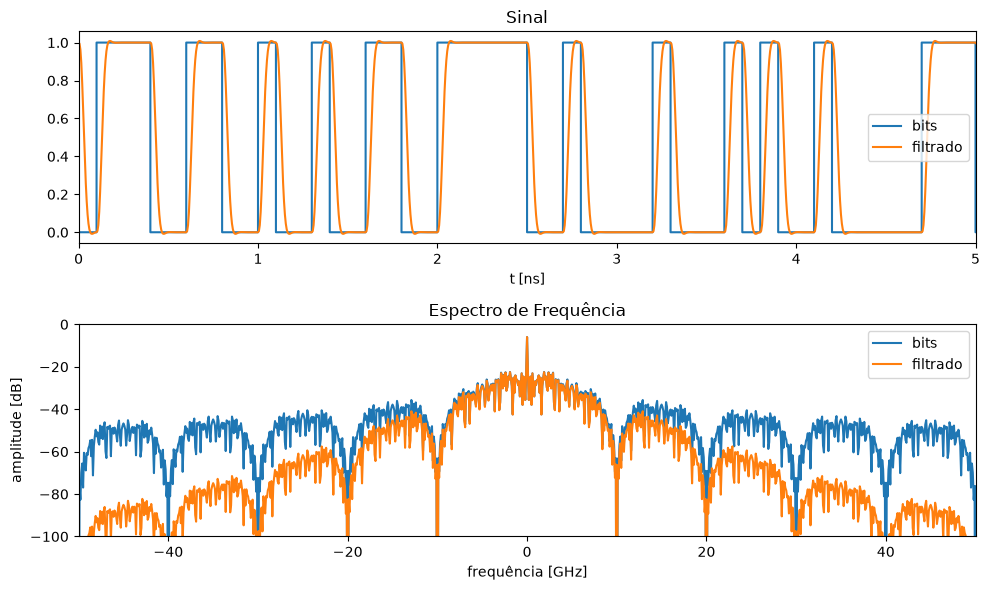

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from simcopy.kernels.filters import apply_response, lowpass_response

#Generator
def generate_binary_data(n_bits: int, seed: int = 1) -> np.ndarray:
    """
    Generate an array of bits in On-Off signalization
    Args:
        n_bits (int)
        seed (int): semente (a mesma semente dá a mesma sequência)
    Returns:
        np.ndarray
    """
    rng = np.random.default_rng(seed)
    return rng.integers(0, 2, n_bits)

def bessel_filter(signal: np.ndarray, fs: float, bandwidth: float, order: int = 4) -> np.ndarray:
    """
    Apply the bessel filter
    Args:
        signal (np.ndarray): sinal amostrado a fs
        fs (float): taxa de amostragem [Hz]
        bandwidth (float): banda de -3 dB [Hz]
        order (int): ordem do filtro
    Returns:
        np.ndarray: array of shape (len(signal),)
    """
    freq = np.fft.fftfreq(signal.size, 1 / fs)
    return apply_response(signal, lowpass_response(freq, bandwidth, "bessel", order))

n_bits = 100
sps = 20
Rb = 10e9                 # taxa de bits
fs = Rb * sps             # taxa de amostragem

# Generate NRZ data
bits = generate_binary_data(n_bits)
electrical_signal = np.repeat(bits, sps).astype(float)       # NRZ
signal = bessel_filter(electrical_signal, fs, bandwidth=Rb)  # -3 dB em 10 GHz

time = np.arange(electrical_signal.size) / fs
fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].plot(time * 1e9, electrical_signal, drawstyle='steps-post', label='bits')
ax[0].plot(time * 1e9, signal, label='filtrado')
ax[0].set(xlabel="t [ns]", xlim=(0, 5), title='Sinal')
ax[0].legend()

f = np.fft.fftshift(np.fft.fftfreq(electrical_signal.size, 1 / fs))
S_bits = np.fft.fftshift(np.abs(np.fft.fft(electrical_signal))) / electrical_signal.size
S_filt = np.fft.fftshift(np.abs(np.fft.fft(signal))) / signal.size

ax[1].plot(f / 1e9, 20 * np.log10(S_bits + 1e-12), label='bits')
ax[1].plot(f / 1e9, 20 * np.log10(S_filt + 1e-12), label='filtrado')
ax[1].set(xlabel='frequência [GHz]', ylabel='amplitude [dB]', xlim=(-50, 50), ylim=(-100, 0),
          title='Espectro de Frequência')
ax[1].legend()

plt.tight_layout()
plt.show()

## Ajuste do sinal ao simcopy

No simcopy, cada sinal precisa ser embalado em uma classe. Todo sinal é, somente, um array e, para que ele seja representativo no sistema, ele precisa ter informações como domínio, geometria do sinal, e precisa ter uma escala de tempo correspondente.

O bloco `NRZDriver` do simcopy faz as duas coisas de uma vez (NRZ + filtro, já embalado em `Waveform`). Abaixo conferimos que ele dá o mesmo sinal.

diferença máxima para o NRZDriver: 0.0


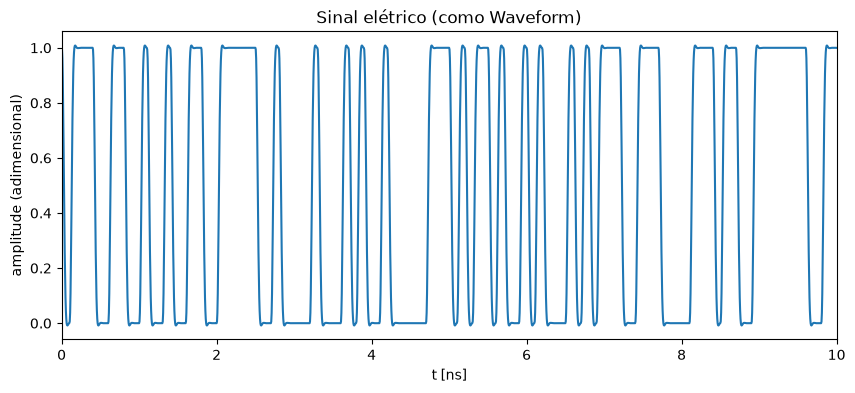

In [2]:
from simcopy.components.tx.driver import NRZDriver
from simcopy.config.system import ElectricalFilterConfig
from simcopy.core.context import SimContext
from simcopy.core.grid import TimeGrid
from simcopy.core.signals import Bits, Domain, SignalGeometry, Waveform
from simcopy.core.units import C_LIGHT

f0 = C_LIGHT / 1550e-9    # frequência do canal

# Essa transformação é necessária para que o sinal se torne representativo no sistema
grid = TimeGrid(fs, signal.size)
geometry = SignalGeometry(n_symbols=n_bits, bits_per_symbol=1, samples_per_symbol=sps, n_pol=1)
electrical_waveform = Waveform(samples=signal.astype(complex)[None, :], grid=grid,
                               domain=Domain.ELECTRICAL, geometry=geometry, channel_id=0)
ctx = SimContext(grid=grid, root_seed=1)

# o mesmo pelo bloco do simcopy
driver = NRZDriver(Rb, ElectricalFilterConfig(filter_order=4, bandwidth_factor=1.0), channel_id=0)
driver_waveform = driver(Bits(bits[None, :].astype(np.uint8), geometry), ctx)
print("diferença máxima para o NRZDriver:",
      np.abs(driver_waveform.samples - electrical_waveform.samples).max())

fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.plot(grid.time * 1e9, electrical_waveform.samples[0].real)
ax.set(xlim=(0, 10), xlabel="t [ns]", ylabel="amplitude (adimensional)",
       title="Sinal elétrico (como Waveform)")
plt.show()

## Laser

Colocamos o laser e vemos a saída óptica para a entrada elétrica acima. O laser de modulação direta (equações de taxa, notebook 02) recebe a corrente $I(t) = I_{th}(1{,}2 + 1{,}8\,x(t))$, com $x(t)$ o sinal elétrico em [0, 1].

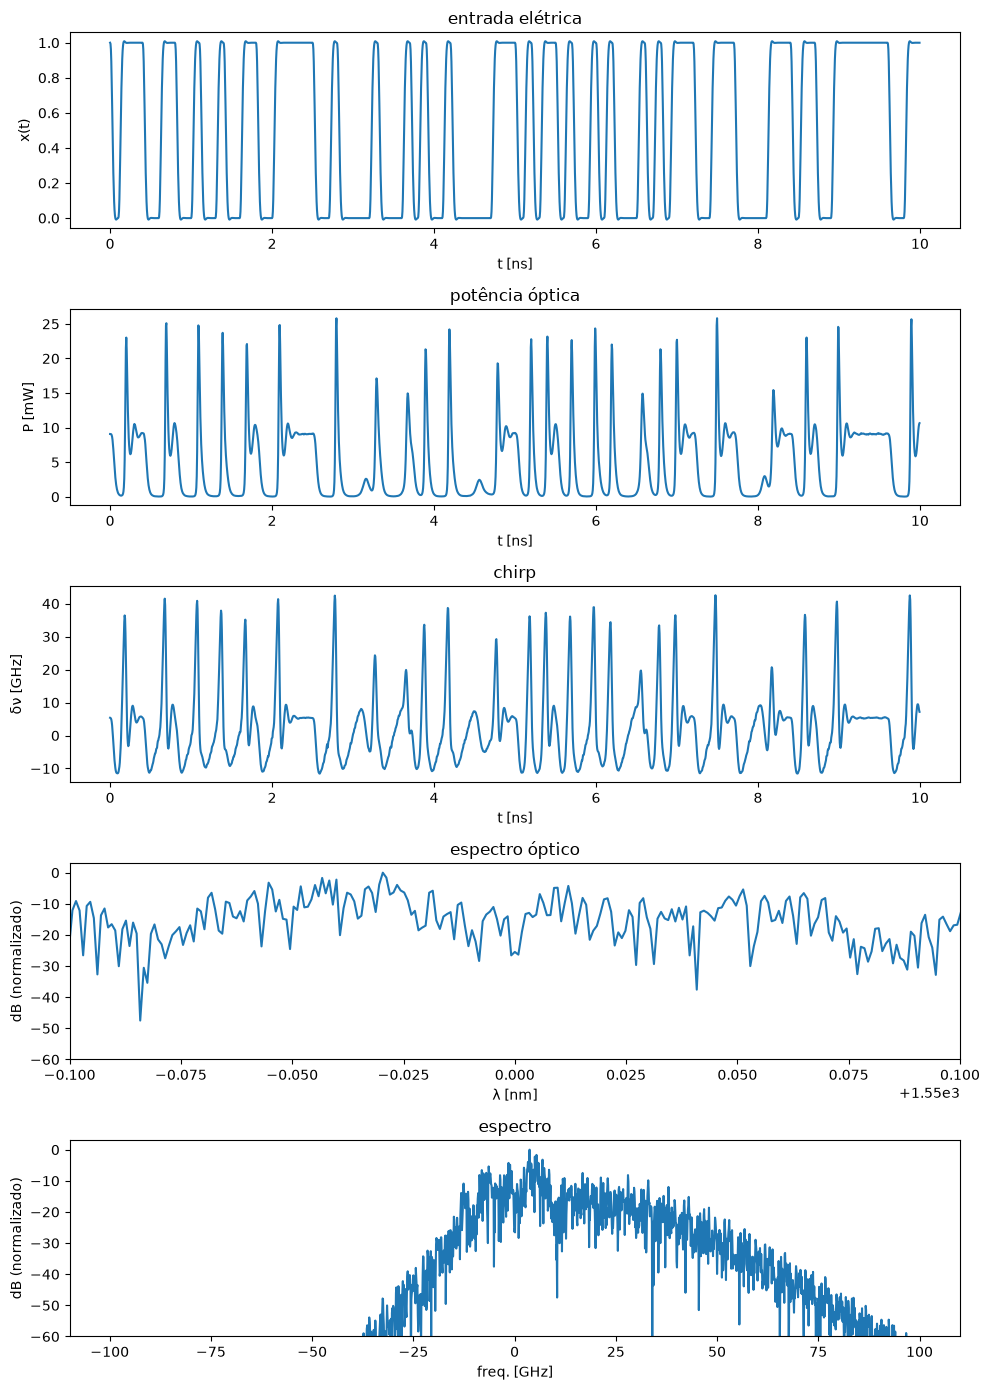

In [3]:
from simcopy.components.tx.laser import DirectModulatedLaser
from simcopy.config.system import RateEquationLaserConfig

# Agora é preciso configurar o laser
cavity_volume = 300e-6 * 3e-6 * 0.2e-6
laser_config = RateEquationLaserConfig(
    cavity_length=300e-6, cavity_width=3e-6, cavity_height=0.2e-6, group_index=3.4,
    mirror_loss=2410.0, internal_loss=1510.0, differential_gain=4e-20,
    transparency_density=1.25e24, confinement=1.0, carrier_lifetime=2.1e-9,
    spontaneous_emission_factor=1.5, gain_compression=1e-7 * cavity_volume,
    linewidth_enhancement=3.0)
laser = DirectModulatedLaser(laser_config, f0, bias_ratio=1.2, modulation_ratio=1.8)  # I = I_th·(1,2 + 1,8·x)

optical_waveform = laser(electrical_waveform, ctx)
optical_field = optical_waveform.samples[0]
time = grid.time

# Para analisar o sinal, vamos obter sua potência e chirp
optical_power = np.abs(optical_field) ** 2
chirp_frequency = -np.gradient(np.unwrap(np.angle(optical_field)), grid.dt) / (2 * np.pi)

# Também vamos obter seu espectro óptico
hann_window = np.hanning(optical_field.size)   # janela por conta da fase
spectrum_power = np.fft.fftshift(np.abs(np.fft.fft(optical_field * hann_window)) ** 2)
relative_optical_frequency = np.fft.fftshift(grid.optical_frequency)
wavelength = C_LIGHT / (f0 + relative_optical_frequency)

fig, ax = plt.subplots(5, 1, figsize=(10, 14))
ax[0].plot(time * 1e9, electrical_waveform.samples[0].real)
ax[0].set(xlabel="t [ns]", ylabel="x(t)", title="entrada elétrica")
ax[1].plot(time * 1e9, optical_power * 1e3)
ax[1].set(xlabel="t [ns]", ylabel="P [mW]", title="potência óptica")
ax[2].plot(time * 1e9, chirp_frequency / 1e9)
ax[2].set(xlabel="t [ns]", ylabel="δν [GHz]", title="chirp")
ax[3].plot(wavelength * 1e9, 10 * np.log10(spectrum_power / spectrum_power.max() + 1e-15))
ax[3].set(xlabel="λ [nm]", ylabel="dB (normalizado)", xlim=(1549.9, 1550.1), ylim=(-60, 3),
          title="espectro óptico")
# Espectro em frequência
ax[4].plot(relative_optical_frequency / 1e9, 10 * np.log10(spectrum_power / spectrum_power.max() + 1e-15))
ax[4].set(xlabel="freq. [GHz]", ylabel="dB (normalizado)", ylim=(-60, 3), title="espectro")
plt.tight_layout()
plt.show()

## Setup Laser + Fibra

Agora, vamos passar esse laser por uma fibra e analisar sua saída óptica. A fibra é o bloco `Fiber` do simcopy: recebe a configuração e a frequência central, como o laser, e chama o SSFM. Desligamos a PMD para isolar atenuação, dispersão e efeito Kerr.

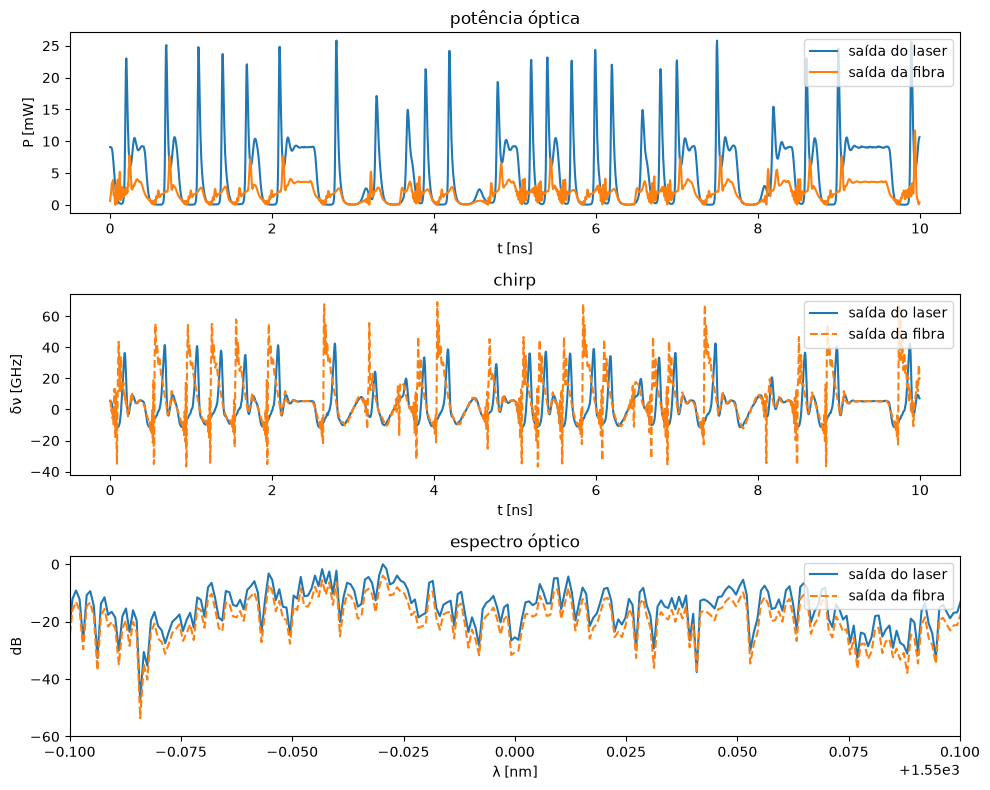

In [4]:
from simcopy.components.optical.fiber import Fiber
from simcopy.config.system import BirefringenceConfig, FiberConfig

# configs da fibra
fiber_config = FiberConfig(length=20e3, birefringence=BirefringenceConfig(enabled=False))
fiber_20km = Fiber(fiber_config, f0)             # converte para SI e chama o SSFM

# obter onda e campo
fiber_waveform = fiber_20km(optical_waveform, ctx)   # mesma grade, canal e f0
fiber_field = fiber_waveform.samples[0]

# Mesmas grandezas da saída do laser, agora para a saída da fibra
fiber_power = np.abs(fiber_field) ** 2
fiber_chirp_frequency = -np.gradient(np.unwrap(np.angle(fiber_field)), grid.dt) / (2 * np.pi)

# Também vamos obter seu espectro óptico
fiber_spectrum_power = np.fft.fftshift(np.abs(np.fft.fft(fiber_field * hann_window)) ** 2)

lc, fc = "tab:blue", "tab:orange"
fig, ax = plt.subplots(3, 1, figsize=(10, 8))
ax[0].plot(time * 1e9, optical_power * 1e3, color=lc, label="saída do laser")
ax[0].plot(time * 1e9, fiber_power * 1e3, color=fc, label="saída da fibra")
ax[0].set(xlabel="t [ns]", ylabel="P [mW]", title="potência óptica")

ax[1].plot(time * 1e9, chirp_frequency / 1e9, color=lc, label="saída do laser")
ax[1].plot(time * 1e9, fiber_chirp_frequency / 1e9, color=fc, label="saída da fibra", linestyle="--")
ax[1].set(xlabel="t [ns]", ylabel="δν [GHz]", title="chirp")

ax[2].plot(wavelength * 1e9, 10 * np.log10(spectrum_power / spectrum_power.max() + 1e-15),
           color=lc, label="saída do laser")
ax[2].plot(wavelength * 1e9, 10 * np.log10(fiber_spectrum_power / spectrum_power.max() + 1e-15),
           color=fc, label="saída da fibra", linestyle="--")
ax[2].set(xlabel="λ [nm]", ylabel="dB", xlim=(1549.9, 1550.1), ylim=(-60, 3),
          title="espectro óptico")
for a in ax:
    a.legend(loc="upper right")
plt.tight_layout()
plt.show()

## Métricas ao longo da distância

Vamos analisar os efeitos da fibra conforme a distância aumenta

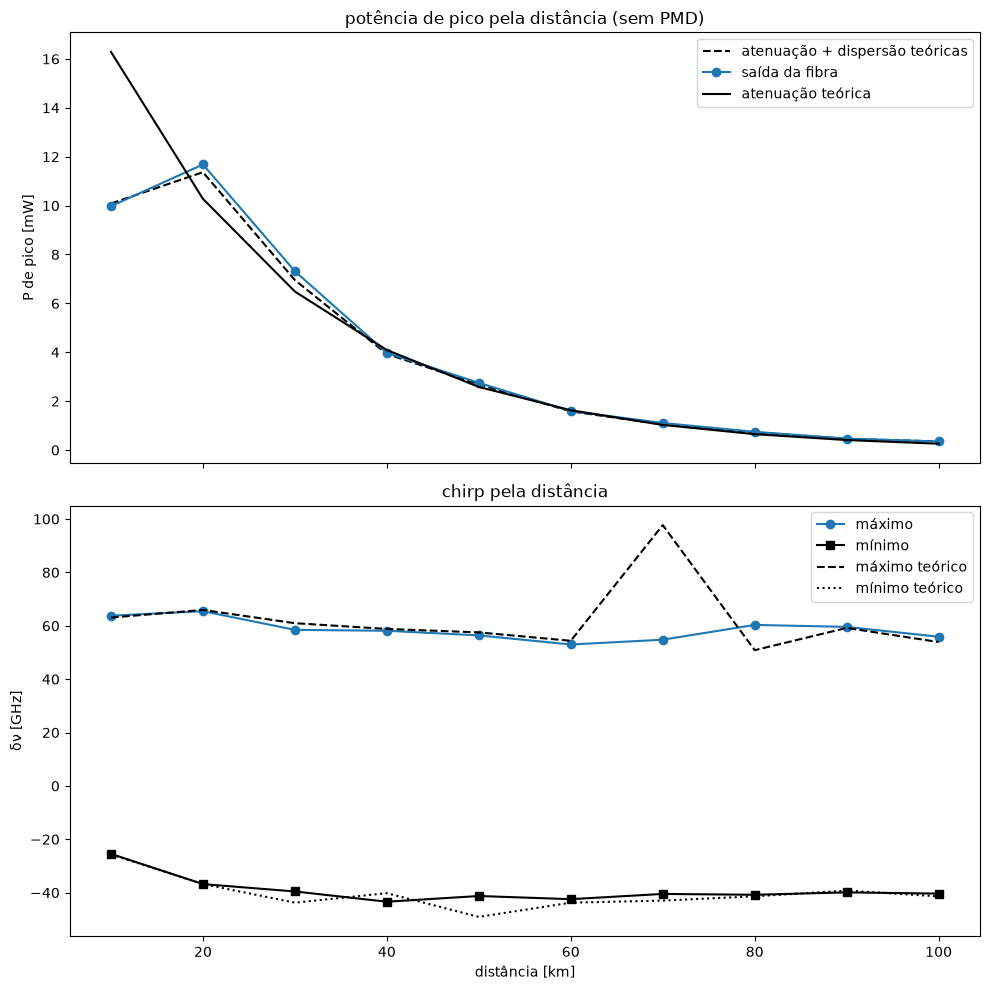

In [5]:
distances = np.arange(10e3, 100e3 + 1, 10e3)     # 10 a 100 km
mean_power_db = []
peak_powers = []
chirp_max = []
chirp_min = []
dispersion_only_peaks = []
theory_chirp_max = []
theory_chirp_min = []
laser_field_spectrum = np.fft.fft(optical_field)
for distance in distances:
    # mesmo que antes, mas agora para cada distância
    fiber = Fiber(FiberConfig(length=distance, birefringence=BirefringenceConfig(enabled=False)), f0)
    output_field = fiber(optical_waveform, ctx).samples[0]
    output_power = np.abs(output_field) ** 2
    output_chirp = -np.gradient(np.unwrap(np.angle(output_field)), grid.dt) / (2 * np.pi)
    output_chirp[output_power < 0.02 * output_power.max()] = np.nan   # fase indefinida onde P ~ 0
    mean_power_db.append(10 * np.log10(output_power.mean() / optical_power.mean()))
    peak_powers.append(output_power.max())
    chirp_max.append(np.nanmax(output_chirp))
    chirp_min.append(np.nanmin(output_chirp))

    # cálculo teórico da dispersão, para comparação com a simulação
    # aqui não usamos efeito Kerr
    dispersed_field = np.fft.ifft(laser_field_spectrum * np.exp(0.5j * fiber.params.beta2 * grid.omega ** 2 * distance))
    dispersion_only_peaks.append((np.abs(dispersed_field) ** 2).max())

    # chirp teórico
    dispersed_power = np.abs(dispersed_field) ** 2
    dispersed_chirp = -np.gradient(np.unwrap(np.angle(dispersed_field)), grid.dt) / (2 * np.pi)
    dispersed_chirp[dispersed_power < 0.02 * dispersed_power.max()] = np.nan
    theory_chirp_max.append(np.nanmax(dispersed_chirp))
    theory_chirp_min.append(np.nanmin(dispersed_chirp))


attenuation_db = -fiber_config.attenuation * distances
attenuation_only = optical_power.max() * 10 ** (attenuation_db / 10)
dispersion_only = np.array(dispersion_only_peaks)
attenuation_and_dispersion = dispersion_only * 10 ** (attenuation_db / 10)

fig, ax = plt.subplots(2, 1, figsize=(10, 10), sharex=True)

ax[0].plot(distances / 1e3, attenuation_and_dispersion * 1e3, color="k", linestyle="--",
           label="atenuação + dispersão teóricas")
ax[0].plot(distances / 1e3, np.array(peak_powers) * 1e3, color="tab:blue", marker="o",
           label="saída da fibra")
ax[0].set(ylabel="P de pico [mW]", title="potência de pico pela distância (sem PMD)")
ax[0].plot(distances / 1e3, attenuation_only * 1e3, color="k", linestyle="-", label="atenuação teórica")
ax[0].legend()
ax[1].plot(distances / 1e3, np.array(chirp_max) / 1e9, color="tab:blue", marker="o", label="máximo")
ax[1].plot(distances / 1e3, np.array(chirp_min) / 1e9, color="k", marker="s", label="mínimo")
ax[1].plot(distances / 1e3, np.array(theory_chirp_max) / 1e9, color="k", linestyle="--", label="máximo teórico")
ax[1].plot(distances / 1e3, np.array(theory_chirp_min) / 1e9, color="k", linestyle=":", label="mínimo teórico")
ax[1].set(xlabel="distância [km]", ylabel="δν [GHz]", title="chirp pela distância")
ax[1].legend()
plt.tight_layout()
plt.show()

## Laser + Fibra + Fotodetector

O fotodetector converte a saída óptica em corrente, retornando ao domínio elétrico. Monitoramos a saída de cada etapa, e comparamos com o caso sem fibra. O fotodetector é o bloco `Photodiode` do simcopy: corrente $R\,P$, ruído de disparo e térmico e o filtro de Bessel de ordem 4 com banda de 1,15·$R_b$.

fotodetector: I média = 1.987 mA (R·P = 1.988 mA), banda = 11.50 GHz


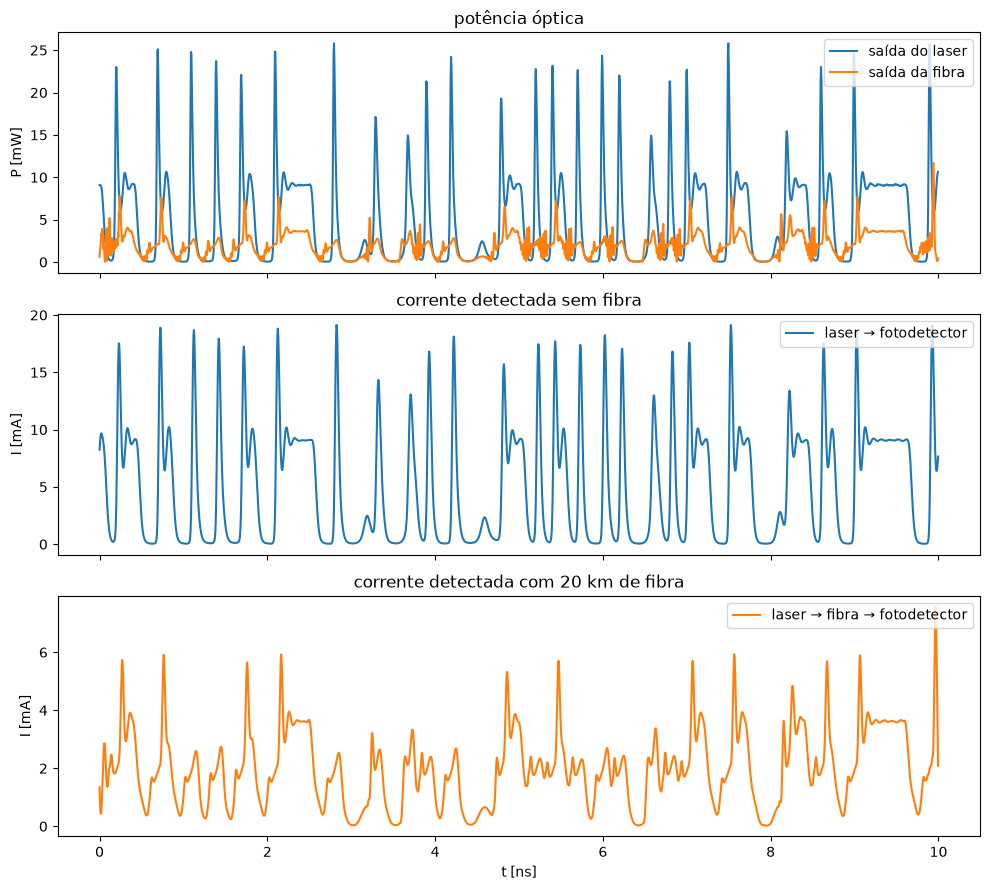

In [6]:
from simcopy.components.rx.photodiode import Photodiode
from simcopy.config.system import PhotodiodeConfig

photodiode_config = PhotodiodeConfig()
photodiode = Photodiode(photodiode_config, Rb)
laser_current = photodiode(optical_waveform, ctx)      # laser -> fotodetector (sem fibra)
fiber_current = photodiode(fiber_waveform, ctx)        # laser -> fibra -> fotodetector

print(f"fotodetector: I média = {fiber_current.samples[0].real.mean() * 1e3:.3f} mA "
      f"(R·P = {photodiode_config.responsivity * fiber_waveform.power * 1e3:.3f} mA), "
      f"banda = {photodiode_config.bandwidth_factor * Rb / 1e9:.2f} GHz")

fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
ax[0].plot(time * 1e9, optical_power * 1e3, color="tab:blue", label="saída do laser")
ax[0].plot(time * 1e9, fiber_power * 1e3, color="tab:orange", label="saída da fibra")
ax[0].set(ylabel="P [mW]", title="potência óptica")
ax[0].legend(loc="upper right")
ax[1].plot(time * 1e9, laser_current.samples[0].real * 1e3, color="tab:blue", label="laser → fotodetector")
ax[1].set(ylabel="I [mA]", title="corrente detectada sem fibra")
ax[1].legend(loc="upper right")
ax[2].plot(time * 1e9, fiber_current.samples[0].real * 1e3, color="tab:orange", label="laser → fibra → fotodetector")
ax[2].set(xlabel="t [ns]", ylabel="I [mA]", title="corrente detectada com 20 km de fibra")
ax[2].legend(loc="upper right")
plt.tight_layout()
plt.show()

## Laser + MZM + Fibra + Fotodetector

Para usar o MZM, vamos trocar o laser de modulação direta por um laser de onda contínua com um MZM depois. O MZM fica em push-pull na quadratura ($V_b = V_\pi/2$), e cada braço recebe $v = 0{,}25\,V_\pi(2x - 1)$: com $x$ indo de 0 a 1, a transmissão vai de 0 a 1 (OOK de nulo a pico). É o bloco `ExternalModulator` do simcopy (laser CW + MZM), aqui com o MZM ideal (sem perda de inserção e com extinção infinita).

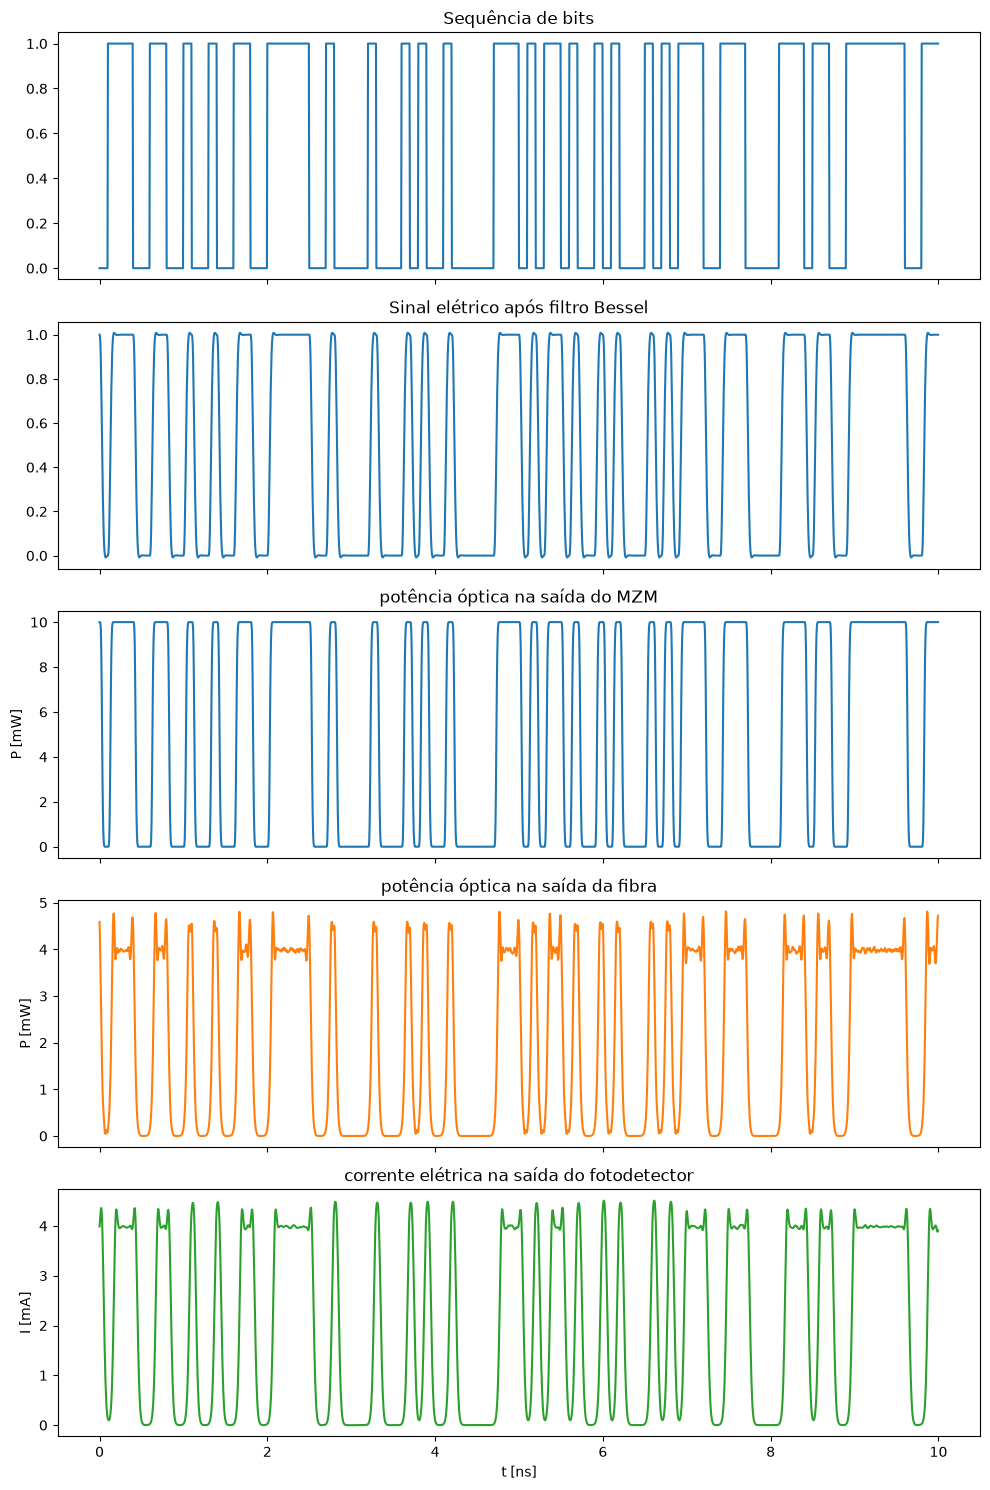

In [7]:
from simcopy.components.tx.modulator import ExternalModulator
from simcopy.config.system import CWLaserConfig, MZMConfig

# passar pelo laser e pelo mzm
mzm_config = MZMConfig(vpi=5.0, vbias=2.5, insertion_loss_db=0.0, extinction_ratio_db=np.inf)   # quadratura
modulator = ExternalModulator(CWLaserConfig(power=10e-3, linewidth=500e3), mzm_config, f0,
                              drive_amplitude=0.25)
mzm_waveform = modulator(electrical_waveform, ctx)

# passar pela fibra
mzm_fiber_waveform = fiber_20km(mzm_waveform, ctx)

# passar pelo fotodetector
mzm_current = photodiode(mzm_fiber_waveform, ctx)

fig, ax = plt.subplots(5, 1, figsize=(10, 15), sharex=True)

# plotar sequencia de bits
ax[0].plot(time * 1e9, electrical_signal, label='bits')
ax[0].set_title('Sequência de bits')
# plotar sequencia de bits apos filtro
ax[1].plot(time * 1e9, signal, label='sinal filtrado')
ax[1].set_title('Sinal elétrico após filtro Bessel')
# plotar saída do mzm
ax[2].plot(time * 1e9, np.abs(mzm_waveform.samples[0]) ** 2 * 1e3, color="tab:blue", label="saída do MZM")
ax[2].set(ylabel="P [mW]", title="potência óptica na saída do MZM")
# plotar saída da fibra
ax[3].plot(time * 1e9, np.abs(mzm_fiber_waveform.samples[0]) ** 2 * 1e3, color="tab:orange", label="saída da fibra")
ax[3].set(ylabel="P [mW]", title="potência óptica na saída da fibra")
# plotar saída do fotodetector
ax[4].plot(time * 1e9, mzm_current.samples[0].real * 1e3, color="tab:green", label="saída do fotodetector")
ax[4].set(xlabel="t [ns]", ylabel="I [mA]", title="corrente elétrica na saída do fotodetector")
plt.tight_layout()
plt.show()

## Fator Q e BER pela distância

Em sistemas mais complexos, a BER costuma ser alta (ordem de ~$10^{3}$), então para calcular a BER costumamos contar bit por bit. Em IMDD não dá para contar os erros, pois, como a BER é alta, teríamos que simular com ~$10^{10}$ símbolos (para medir uma BER com ~10 % de erro são precisos ~100 erros, ou seja, ~100/BER bits). Para isso, usamos o fator Q, que estima a BER com algumas centenas de bits:

$$Q = \frac{I_1 - I_0}{\sigma_1 + \sigma_0}, \qquad \mathrm{BER} = \tfrac{1}{2}\,\mathrm{erfc}\!\left(\frac{Q}{\sqrt{2}}\right), \qquad I_D = \frac{\sigma_0 I_1 + \sigma_1 I_0}{\sigma_0 + \sigma_1}$$

com $I_1$, $I_0$, $\sigma_1$, $\sigma_0$ a média e o desvio da corrente nos bits 1 e 0, no instante de decisão, e $I_D$ o limiar ótimo.

Daqui em diante, não vamos usar o código passo a passo, que foi apresentado acima por motivos disáticos. Vamos usar o próprio Simcopy, que configura o sistema a partir de um arquivo de configuração:
- `examples/imdd_ook_mzm.yaml`: laser CW + MZM + 20 km + fotodetector (a seção anterior)
- `examples/imdd_ook_dml.yaml` (ou `.json`, o mesmo cenário): laser de modulação direta + 20 km + fotodetector.

Os bits de cada canal saem só da seed de cada canal, e os ruídos saem da seed da simulação (`root_seed`): trocar `root_seed` muda os ruídos e mantém os bits. O `run` monta os blocos, roda e mede Q: escolhe o instante de decisão que maximiza Q (os bits transmitidos são conhecidos) e descarta os símbolos das bordas da janela, contaminados pela janela periódica da FFT ($\lceil R_b(\pi|\beta_2|L f_s + 1\,\mathrm{ns})\rceil + 1$ em cada borda). Os arquivos usam 2048 bits e 16 amostras por bit.

modulação externa: canal 0: Q = 26.608 (28.50 dB) | BER por Q = 2.740e-156 | erros contados = 0/2020 | potencia recebida = 3.00 dBm | instante = 21 amostras | simbolos 14 a 2033
modulação direta:  canal 0: Q = 1.511 (3.59 dB) | BER por Q = 6.537e-02 | erros contados = 42/2020 | potencia recebida = 2.99 dBm | instante = 16 amostras | simbolos 14 a 2033


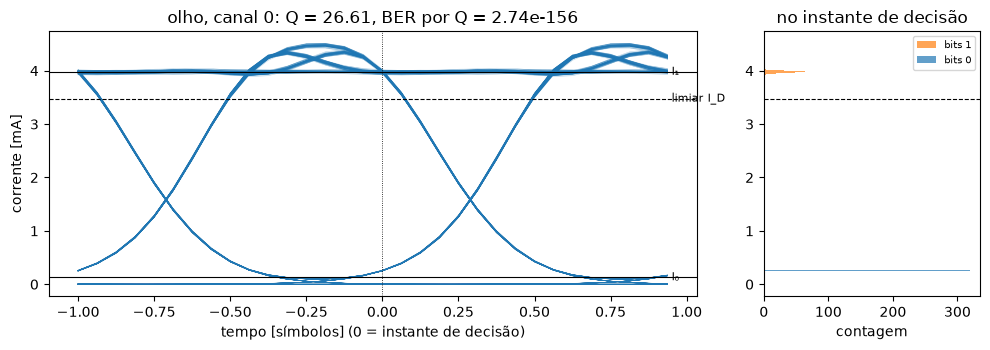

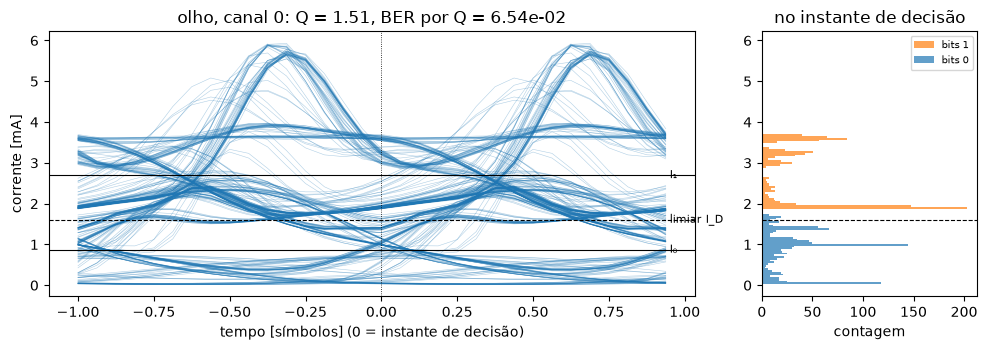

In [8]:
from pathlib import Path

import simcopy
from simcopy.config.io import load
from simcopy.core.units import w_to_dbm
from simcopy.pipelines.runner import run, sweep
from simcopy.plotting import plot_chain, plot_eye, plot_stage, plot_sweep

# os exemplos ficam na raiz do repositório, qualquer que seja a pasta em que o notebook roda
examples = Path(simcopy.__file__).parents[2] / "examples"

mzm_system, mzm_simulation = load(examples / "imdd_ook_mzm.yaml")
dml_system, dml_simulation = load(examples / "imdd_ook_dml.yaml")

mzm = run(mzm_system, mzm_simulation)      # laser CW + MZM, 20 km
dml = run(dml_system, dml_simulation)      # laser de modulação direta, 20 km
print("modulação externa:", mzm.summary())
print("modulação direta: ", dml.summary())

plot_eye(mzm)
plot_eye(dml)
plt.show()

 L [km] | externa: Q    BER por Q   erros | direta: Q    BER por Q   erros
     20 |        26.61   2.74e-156      0 |      1.51    6.54e-02     42
     21 |        25.89   4.82e-148      0 |      1.36    8.62e-02     72
     22 |        24.91   2.61e-137      0 |      1.23    1.10e-01     87
     23 |        23.68   2.72e-124      0 |      1.11    1.34e-01     98
     24 |        22.25   5.11e-110      0 |      1.06    1.44e-01    257
     25 |        20.75    6.12e-96      0 |      1.08    1.41e-01    243
     26 |        19.42    2.74e-84      0 |      1.09    1.38e-01    174
     27 |        18.22    1.93e-74      0 |      1.10    1.35e-01    161
     28 |        17.22    9.49e-67      0 |      1.11    1.33e-01    161
     29 |        16.40    9.61e-61      0 |      1.12    1.32e-01    155
     30 |        16.14    6.19e-59      0 |      1.13    1.30e-01    203
     31 |        15.78    2.12e-56      0 |      1.14    1.28e-01    204
     32 |        15.32    2.98e-53      0 |      

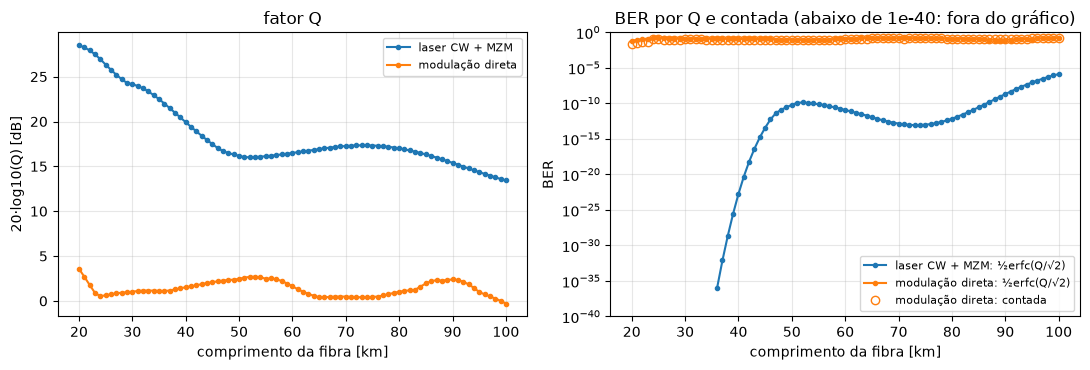

In [16]:
# 20 a 100 km, passo de 10 km. O transmissor não depende do comprimento da fibra e roda uma vez só
lengths = np.arange(20e3, 100e3 + 1, 10e3)
mzm_sweep = sweep(mzm_system, mzm_simulation, "link.spans[0].fiber.length", lengths)
dml_sweep = sweep(dml_system, dml_simulation, "link.spans[0].fiber.length", lengths)

print(" L [km] | externa: Q    BER por Q   erros | direta: Q    BER por Q   erros")
for k, L in enumerate(lengths):
    a, b = mzm_sweep.metrics[k][0], dml_sweep.metrics[k][0]
    print(f"{L / 1e3:7.0f} | {a.q:12.2f} {a.ber_q:11.2e} {a.errors:6d} | "
          f"{b.q:9.2f} {b.ber_q:11.2e} {b.errors:6d}")

plot_sweep([mzm_sweep, dml_sweep], labels=["laser CW + MZM", "modulação direta"])
plt.show()

Com o laser CW + MZM, Q vai de 26,6 (20 km) a 9,9 (40 km), sem nenhum erro contado: a BER pela fórmula vai de 3e-156 a 2e-23, zero na prática. Quem limita é a dispersão, porque o receptor recebe 3 dBm e o ruído quase não pesa. Aqui Q mede a abertura do olho.

Com o laser de modulação direta, Q = 1,5 a 20 km (42 erros) e fica perto de 1 a partir de 24 km: o chirp do laser (seção Laser) vira distorção de intensidade na fibra e o olho fecha. Com o olho fechado as distribuições deixam de ser gaussianas e a fórmula vale menos. Mas aí já há erros para contar, e a BER contada (círculos) fica perto da estimada: de 24 a 40 km, 153 a 257 erros em 2020 bits (0,08 a 0,13), contra 0,12 a 0,14 pela fórmula.

## Duas fibras: SMF + DCF

Colocamos uma fibra compensadora de dispersão (DCF) depois da fibra padrão (SMF). A DCF tem dispersão normal ($D < 0$), e o comprimento que zera a dispersão acumulada sai de $D_1L_1 + D_2L_2 = 0$ (Agrawal, Eq. 8.2.3). Valores típicos de DCF (Agrawal, seção 8.2): $D = -100$ ps/(km·nm), perda de ~0,5 dB/km e $A_{eff}$ de ~20 µm², o que aumenta $\gamma$ por um fator ~4. Para 60 km de SMF são 9,6 km de DCF.

No simcopy, cada elemento de `link.spans` é uma fibra, com um amplificador opcional depois dela. SMF + DCF são então dois elementos. Fazemos com os dois transmissores.

DCF: 9.6 km
modulação direta, só SMF:    canal 0: Q = 1.206 (1.63 dB) | BER por Q = 1.139e-01 | erros contados = 198/2012 | potencia recebida = -5.01 dBm | instante = 21 amostras | simbolos 18 a 2029
modulação direta, SMF + DCF: canal 0: Q = 5.895 (15.41 dB) | BER por Q = 1.872e-09 | erros contados = 0/2000 | potencia recebida = -9.81 dBm | instante = 25 amostras | simbolos 24 a 2023
laser CW + MZM, só SMF:    canal 0: Q = 6.681 (16.50 dB) | BER por Q = 1.186e-11 | erros contados = 0/2012 | potencia recebida = -5.00 dBm | instante = 17 amostras | simbolos 18 a 2029
laser CW + MZM, SMF + DCF: canal 0: Q = 35.952 (31.11 dB) | BER por Q = 2.314e-283 | erros contados = 0/2000 | potencia recebida = -9.80 dBm | instante = 17 amostras | simbolos 24 a 2023


KeyError: "estagio 'ch0.tx.laser' nao existe; estagios: ['ch0.tx.bits', 'ch0.tx.driver', 'ch0.tx.modulator', 'link.span0.fiber', 'link.span1.fiber', 'ch0.rx.photodiode']"

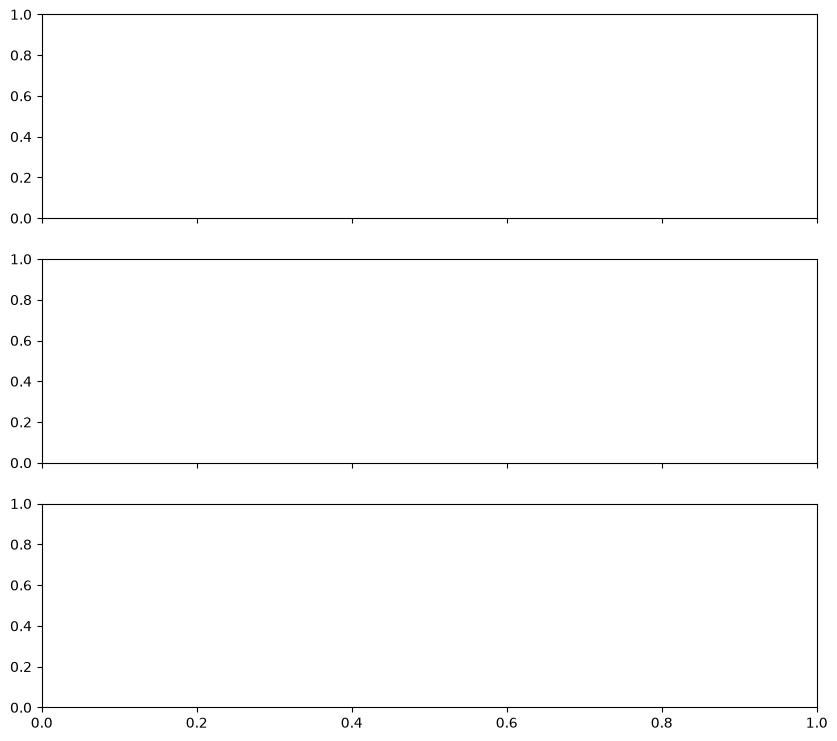

In [17]:
import dataclasses
from simcopy.config.system import SpanConfig

smf = FiberConfig(length=60e3)                                   # SMF: D = 16 ps/(nm km), 0,2 dB/km
dcf_length = smf.length * smf.dispersion / 100e-6                # D1 L1 + D2 L2 = 0
dcf = FiberConfig(length=dcf_length, dispersion=-100e-6, attenuation=0.5e-3, effective_area=20e-12)
print(f"DCF: {dcf_length / 1e3:.1f} km")

def with_link(system, *spans):
    """O mesmo sistema, com outro enlace."""
    return dataclasses.replace(system, link=dataclasses.replace(system.link, spans=spans))

for name, system, simulation in (("modulação direta", dml_system, dml_simulation),
                                 ("laser CW + MZM", mzm_system, mzm_simulation)):
    smf_only = run(with_link(system, SpanConfig(smf)), simulation)
    smf_dcf = run(with_link(system, SpanConfig(smf), SpanConfig(dcf)), simulation, previous=smf_only)
    print(f"{name}, só SMF:   ", smf_only.summary())
    print(f"{name}, SMF + DCF:", smf_dcf.summary())

# monitorando a saída óptica nas duas fibras (último caso: modulação direta)
fig, ax = plt.subplots(3, 1, figsize=(10, 9), sharex=True)
t_ns = smf_dcf.resolved.grid.time * 1e9
for a, sid, title in ((ax[0], "ch0.tx.laser", "saída do laser"),
                      (ax[1], "link.span0.fiber", "saída da SMF (60 km)"),
                      (ax[2], "link.span1.fiber", "saída da DCF")):
    a.plot(t_ns, np.abs(smf_dcf.output(sid).samples[0]) ** 2 * 1e3)
    a.set(ylabel="P [mW]", title=title, xlim=(0, 3))
ax[2].set(xlabel="t [ns]")
plt.tight_layout()

plot_eye(smf_only)
plot_eye(smf_dcf)
plt.show()

Só com a SMF (60 km), Q = 6,7 com o MZM e 1,2 com a modulação direta (198 erros). Com a DCF a dispersão é desfeita: Q = 36,0 com o MZM e 5,9 com a modulação direta. No laser direto sobra o limite do próprio laser (oscilações de relaxação). Na figura, a saída da DCF repete a forma da saída do laser, 17 dB abaixo. O preço é a perda: a potência recebida cai de −5,0 para −9,8 dBm.

## Amplificador depois da DCF

A DCF compensa a dispersão, mas soma perda: a potência recebida caiu cerca de 5 dB. Um amplificador (EDFA) depois da DCF repõe as perdas da SMF e da DCF (12 + 4,8 dB). O preço é o ruído de ASE (notebook 04), que aparece como um piso no espectro óptico.

ganho do EDFA = 16.8 dB
canal 0: Q = 43.504 (32.77 dB) | BER por Q = 0.000e+00 | erros contados = 0/2000 | potencia recebida = 7.00 dBm | instante = 16 amostras | simbolos 24 a 2023
ch0.tx.modulator          7.00 dBm
link.span0.fiber         -5.00 dBm
link.span1.fiber         -9.80 dBm
link.span1.amplifier      7.00 dBm


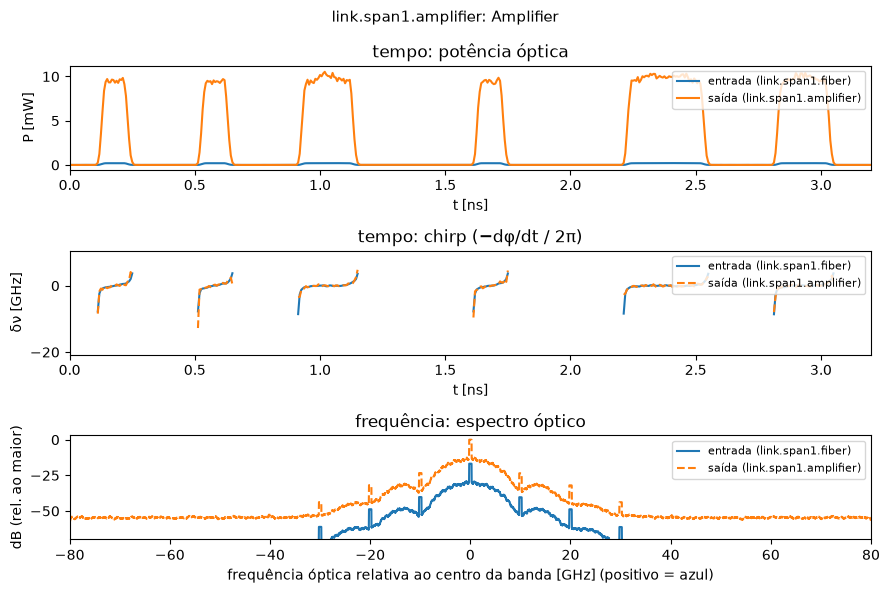

In [11]:
from simcopy.config.system import AmplifierConfig

span_loss_db = smf.attenuation * smf.length + dcf.attenuation * dcf.length     # dB
edfa = AmplifierConfig(mode="fixed_gain", gain_db=span_loss_db, noise_figure_db=5.0)
amplified = run(with_link(mzm_system, SpanConfig(smf), SpanConfig(dcf, amplifier=edfa)), mzm_simulation)
print(f"ganho do EDFA = {span_loss_db:.1f} dB")
print(amplified.summary())

# potência óptica média ao longo do enlace
for sid in amplified.ids:
    output = amplified.output(sid)
    if isinstance(output, Waveform) and output.domain is Domain.OPTICAL:
        print(f"{sid:<22} {w_to_dbm(output.power):7.2f} dBm")

plot_stage(amplified, "link.span1.amplifier")     # entrada e saída do EDFA: piso de ASE no espectro
plt.show()

O EDFA também satura: o coeficiente de ganho cai com a potência como $g = g_0/(1 + P/P_s)$ (Agrawal, Exercício 7.2). Integrando ao longo do amplificador, o ganho satisfaz $\ln G + (G - 1)P_{in}/P_s = \ln G_0$, com $G_0$ o ganho de pequeno sinal. O EDFA responde à potência média, não a cada pulso (Agrawal, seção 7.2.2). No simcopy, isso é o campo `saturation_power` do amplificador de ganho fixo. Usamos $P_s$ = 10 mW, o `SaturationPower` do VPI.

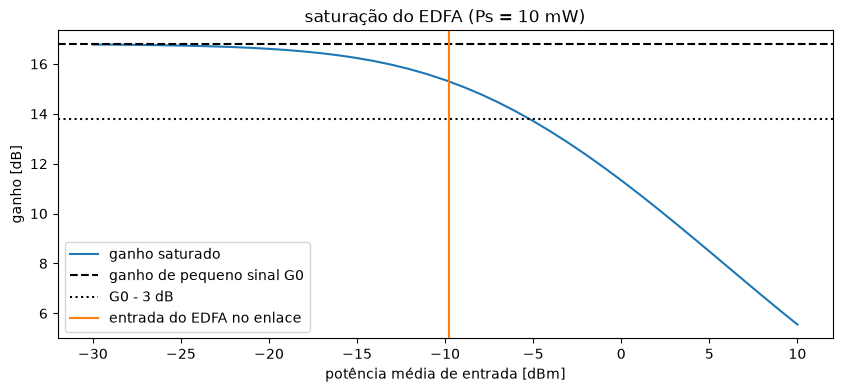

ganho sem saturação: 16.80 dB | com saturação: 15.31 dB
canal 0: Q = 43.458 (32.76 dB) | BER por Q = 0.000e+00 | erros contados = 0/2000 | potencia recebida = 5.50 dBm | instante = 16 amostras | simbolos 24 a 2023


In [12]:
from simcopy.components.optical.amplifier import Amplifier

saturated = AmplifierConfig(mode="fixed_gain", gain_db=span_loss_db, noise_figure_db=5.0,
                            saturation_power=10e-3)
edfa_block = Amplifier(saturated, f0)

# ganho pela potência média de entrada, escalando a entrada do EDFA do enlace acima
edfa_input = amplified.output("link.span1.fiber")
input_dbm = np.arange(-30, 11, 1.0)
gain_db = [10 * np.log10(edfa_block.gain(edfa_input.with_samples(
               edfa_input.samples * np.sqrt(10 ** ((p - w_to_dbm(edfa_input.power)) / 10)))))
           for p in input_dbm]

fig, ax = plt.subplots(1, 1, figsize=(10, 4))
ax.plot(input_dbm, gain_db, label="ganho saturado")
ax.axhline(span_loss_db, color="k", linestyle="--", label="ganho de pequeno sinal G0")
ax.axhline(span_loss_db - 3, color="k", linestyle=":", label="G0 - 3 dB")
ax.axvline(w_to_dbm(edfa_input.power), color="tab:orange", label="entrada do EDFA no enlace")
ax.set(xlabel="potência média de entrada [dBm]", ylabel="ganho [dB]", title="saturação do EDFA (Ps = 10 mW)")
ax.legend()
plt.show()

# o mesmo enlace, com o EDFA saturável
saturated_link = run(with_link(mzm_system, SpanConfig(smf), SpanConfig(dcf, amplifier=saturated)),
                     mzm_simulation, previous=amplified)
print("ganho sem saturação:", f"{span_loss_db:.2f} dB", "| com saturação:",
      f"{10 * np.log10(saturated_link.output('link.span1.amplifier').power / edfa_input.power):.2f} dB")
print(saturated_link.summary())

O EDFA de 16,8 dB devolve a potência da saída do MZM (7,00 → −5,00 → −9,80 → 7,00 dBm), e Q sobe para 43,5. No espectro da saída do amplificador aparece o piso de ASE, ~55 dB abaixo do pico, na banda inteira da simulação.

Com saturação ($P_s$ = 10 mW), a entrada do EDFA no enlace (−9,8 dBm) já comprime o ganho de 16,8 para 15,3 dB, e a potência recebida cai para 5,5 dBm. Q quase não muda (43,5): a ASE sai do mesmo amplificador, com o mesmo ganho. Pela equação, o ganho cai 3 dB com −5,2 dBm na entrada (8,6 dBm na saída).

## Múltiplos spans

Repetimos o trecho SMF + DCF + EDFA $N$ vezes, com 0 dBm lançados por canal (`launch_power`). A dispersão de cada trecho é compensada no próprio trecho, e a ASE de cada amplificador se acumula (Agrawal, Eq. 7.4.1 e 7.4.2, notebook 04): Q cai com o número de trechos.

Fazemos com os dois transmissores, o laser CW + MZM e o de modulação direta, no mesmo enlace. Passando o resultado anterior em `previous`, o simcopy reaproveita o transmissor e os trechos que não mudaram.

laser CW + MZM,  1 trechos (  69.6 km): Q =  59.54 | erros = 0 | P recebida = 0.01 dBm
laser CW + MZM,  2 trechos ( 139.2 km): Q =  40.46 | erros = 0 | P recebida = 0.03 dBm
laser CW + MZM,  4 trechos ( 278.4 km): Q =  26.82 | erros = 0 | P recebida = 0.05 dBm
laser CW + MZM,  6 trechos ( 417.6 km): Q =  21.04 | erros = 0 | P recebida = 0.08 dBm
laser CW + MZM,  8 trechos ( 556.8 km): Q =  17.40 | erros = 0 | P recebida = 0.11 dBm
laser CW + MZM, 10 trechos ( 696.0 km): Q =  14.74 | erros = 0 | P recebida = 0.13 dBm
laser CW + MZM, 15 trechos (1044.0 km): Q =  10.90 | erros = 0 | P recebida = 0.20 dBm
laser CW + MZM, 20 trechos (1392.0 km): Q =   8.75 | erros = 0 | P recebida = 0.26 dBm
modulação direta,  1 trechos (  69.6 km): Q =   5.77 | erros = 0 | P recebida = 0.01 dBm
modulação direta,  2 trechos ( 139.2 km): Q =   5.75 | erros = 0 | P recebida = 0.03 dBm
modulação direta,  4 trechos ( 278.4 km): Q =   5.68 | erros = 0 | P recebida = 0.05 dBm
modulação direta,  6 trechos ( 417.6 

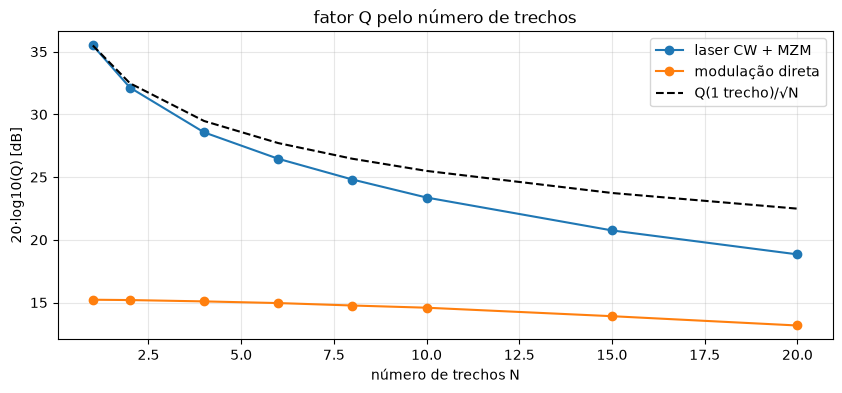

In [13]:
n_spans = [1, 2, 4, 6, 8, 10, 15, 20]
span = [SpanConfig(smf), SpanConfig(dcf, amplifier=edfa)]

q_spans = {}
for name, system, simulation in (("laser CW + MZM", mzm_system, mzm_simulation),
                                 ("modulação direta", dml_system, dml_simulation)):
    channel = dataclasses.replace(system.channels[0], launch_power=1e-3)    # 0 dBm
    system = dataclasses.replace(system, channels=(channel,))
    previous, q_spans[name] = None, []
    for n in n_spans:
        result = run(with_link(system, *(span * n)), simulation, previous=previous)
        previous = result
        q_spans[name].append(result.metrics[0].q)
        print(f"{name}, {n:2d} trechos ({n * (smf.length + dcf.length) / 1e3:6.1f} km): "
              f"Q = {result.metrics[0].q:6.2f} | erros = {result.metrics[0].errors} | "
              f"P recebida = {w_to_dbm(result.received_power()):.2f} dBm")

fig, ax = plt.subplots(1, 1, figsize=(10, 4))
for name, q in q_spans.items():
    ax.plot(n_spans, 20 * np.log10(q), marker="o", label=name)
q1 = q_spans["laser CW + MZM"][0]
ax.plot(n_spans, 20 * np.log10(q1 / np.sqrt(n_spans)), "k--", label="Q(1 trecho)/√N")
ax.set(xlabel="número de trechos N", ylabel="20·log10(Q) [dB]", title="fator Q pelo número de trechos")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

Com o MZM, Q cai de 59,5 (1 trecho, 70 km) para 8,8 (20 trechos, 1392 km), e a potência recebida sobe de 0,01 para 0,26 dBm: é a ASE acumulada. Até 2 trechos a queda segue aproximadamente Q ∝ 1/√N, o batimento sinal-ASE (Agrawal, Eq. 7.5.7). Depois Q cai mais rápido por causa do efeito Kerr acumulado: com $n_2 = 0$ (teste fora do notebook) a queda segue 1/√N até 20 trechos (Q = 13,0 contra 14,5 previsto), e com Kerr fica em 8,8. São 0 dBm por 20 trechos, e a DCF tem $\gamma$ quatro vezes maior.

Com a modulação direta, Q começa em 5,8 e cai devagar, até 4,6 em 20 trechos: quem limita é o próprio laser (oscilações de relaxação), não a ASE. Com a dispersão compensada nos dois casos, só o MZM tem margem para a ASE e para a não linearidade.

## Múltiplos canais

Quatro canais IMDD (laser CW + MZM, 10 Gb/s) espaçados de 50 GHz são somados no mux e propagados juntos pelo mesmo enlace: 80 km de SMF + DCF + EDFA. No receptor, o demux de cada canal filtra o seu canal antes do fotodetector. O filtro do exemplo é supergaussiano de ordem 3, com 30 GHz (três vezes a taxa de bits).

Quem leva cada canal para a sua frequência é o mux, e os transmissores ficam em banda base. O cenário é `examples/imdd_wdm_4ch.yaml`, com 32 amostras por bit para a grade cobrir os quatro canais.

canal 0: Q = 34.919 (30.86 dB) | BER por Q = 1.919e-267 | erros contados = 0/1960 | potencia recebida = -0.01 dBm | instante = 35 amostras | simbolos 44 a 2003
canal 1: Q = 32.770 (30.31 dB) | BER por Q = 7.875e-236 | erros contados = 0/1960 | potencia recebida = -0.01 dBm | instante = 36 amostras | simbolos 44 a 2003
canal 2: Q = 33.912 (30.61 dB) | BER por Q = 2.217e-252 | erros contados = 0/1960 | potencia recebida = -0.01 dBm | instante = 35 amostras | simbolos 44 a 2003
canal 3: Q = 34.663 (30.80 dB) | BER por Q = 1.439e-263 | erros contados = 0/1960 | potencia recebida = -0.01 dBm | instante = 36 amostras | simbolos 44 a 2003


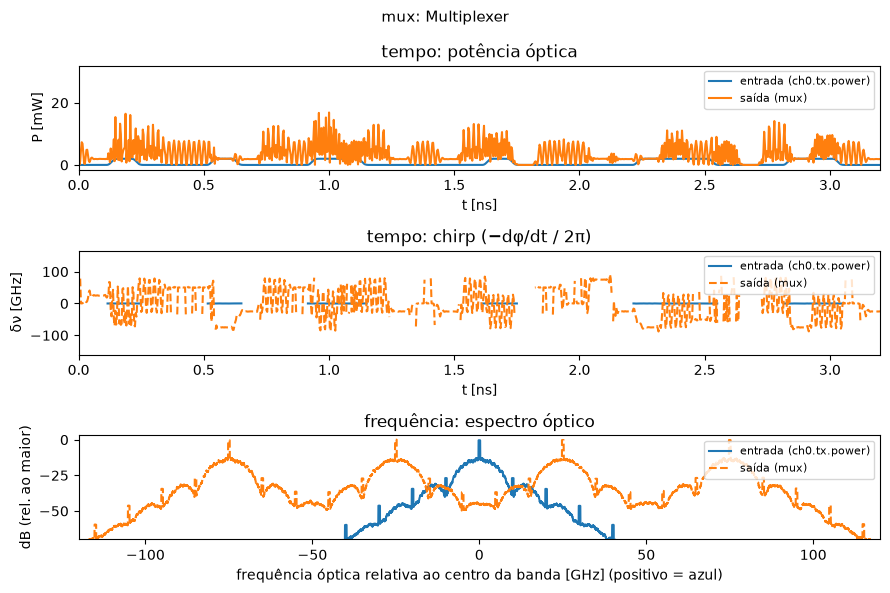

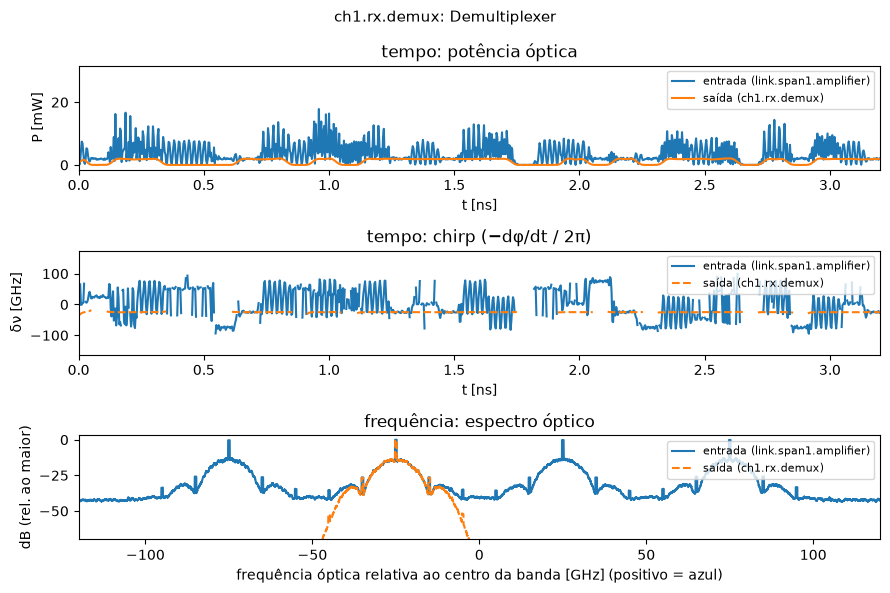

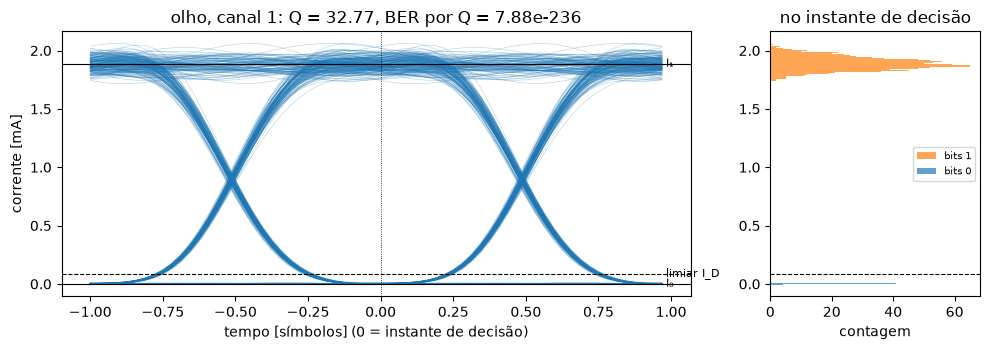

In [14]:
wdm_system, wdm_simulation = load(examples / "imdd_wdm_4ch.yaml")
wdm = run(wdm_system, wdm_simulation)
print(wdm.summary())

plot_stage(wdm, "mux", freq_span=120e9)              # entrada: canal 0, saída: os 4 canais somados
plot_stage(wdm, "ch1.rx.demux", freq_span=120e9)     # demux do canal 1: o campo agregado entra, o canal 1 sai
plot_eye(wdm, 1)
plt.show()

In [15]:
# Aproximando os canais: com o mesmo filtro, os vizinhos passam a vazar no demux (diafonia)
for spacing in (50e9, 37.5e9, 25e9):
    r = run(dataclasses.replace(wdm_system, channel_spacing=spacing), wdm_simulation)
    print(f"espaçamento {spacing / 1e9:4.1f} GHz: Q por canal = "
          + ", ".join(f"{m.q:5.2f}" for m in r.metrics.values()))

alone = run(dataclasses.replace(wdm_system, channels=(wdm_system.channels[1],)), wdm_simulation)
print(f"canal 1 sozinho no enlace: Q = {alone.metrics[1].q:.2f}")

# mux como o do VPI: cada canal passa por um filtro (supergaussiano de ordem 3 com 45 GHz, na proporção
# dos 70 GHz do VPI para 75 GHz entre canais) e o mux tem 3 dB de perda
from simcopy.config.system import MuxConfig, OpticalFilterConfig
vpi_mux = MuxConfig(insertion_loss_db=3.0,
                    optical_filter=OpticalFilterConfig(bandwidth=45e9, filter_type="supergaussian", filter_order=3))
r = run(dataclasses.replace(wdm_system, mux=vpi_mux), wdm_simulation)
print("mux com filtro e 3 dB de perda: Q por canal = " + ", ".join(f"{m.q:5.2f}" for m in r.metrics.values())
      + f" | potência na saída do mux = {w_to_dbm(r.output('mux').power):.2f} dBm"
      + f" (ideal: {w_to_dbm(wdm.output('mux').power):.2f} dBm)")

espaçamento 50.0 GHz: Q por canal = 34.92, 32.77, 33.91, 34.66
espaçamento 37.5 GHz: Q por canal = 35.17, 32.37, 32.00, 34.24
espaçamento 25.0 GHz: Q por canal = 28.73, 22.29, 22.68, 27.74
canal 1 sozinho no enlace: Q = 34.03
mux com filtro e 3 dB de perda: Q por canal = 24.23, 24.22, 24.24, 24.52 | potência na saída do mux = 3.02 dBm (ideal: 6.02 dBm)


Com 50 GHz entre canais, os quatro chegam com ~0 dBm e Q de 32,8 a 34,9, o mesmo do canal 1 sozinho no enlace (34,0): o filtro de 30 GHz separa bem os canais. O demux também corta ASE: sozinho e sem demux, o canal 1 tem Q = 30,8 (teste fora do notebook). Aproximando os canais para 25 GHz, com o mesmo filtro, Q cai para 22 a 29. Os canais do meio (1 e 2) perdem mais, porque têm dois vizinhos. É diafonia linear no demux (Agrawal, Eq. 6.3.1): o espectro dos vizinhos vaza pelo filtro. Sem efeito Kerr (teste fora do notebook), Q a 25 GHz fica quase igual (28,2 / 22,8 / 22,6 / 26,5).

Com o mux como o do VPI (filtro por canal e 3 dB de perda), Q cai para ~24. Os 3 dB de perda tiram potência de sinal antes do EDFA, que soma a mesma ASE. A queda (34 → 24, fator ~√2) condiz com isso.

No espectro do mux, cada canal está na sua posição (−75, −25, +25 e +75 GHz). A saída do demux do canal 1 fica em −25 GHz, e a corrente detectada não depende disso.

## O mesmo pela linha de comando

Qualquer cenário IMDD em YAML ou JSON roda sem notebook (na pasta `repo/`):

```
simcopy run examples/imdd_ook_dml.json -o resultados/dml
simcopy run examples/imdd_wdm_4ch.yaml -o resultados/wdm
simcopy sweep examples/imdd_ook_mzm.yaml --param "link.spans[0].fiber.length" --range 20e3 40e3 1e3 -o resultados/mzm
```

`run` imprime o tempo de cada estágio e as métricas. Com `-o`, grava `metricas.json` e os gráficos (a cadeia e o olho de cada canal e um gráfico por estágio). `sweep` grava `varredura.json` e a curva de Q e BER. O guia é `docs/sistema_imdd.md`.